<a href="https://colab.research.google.com/github/davichomendez1901-byte/Simulaci-n-Remix/blob/main/SIR_c_n_pyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Modelo SIR mediante inferencia bayesiana con PyMC.

Para realizar el ajuste bayesiano de los parámetros del modelo SIR se utilizará la libria **PyMC**, para la construcción de modelos probabilísticos y la inferencia bayesiana.


También se utilizarán **NUmpy** para operaciones numericas y **matplotlib** para la visualización de resultados y **ArviZ** para el análisis de las muestras obtenidas mediante PyMC.

In [1]:
import pymc as pm
import numpy as np
import matplotlib.pyplot as plt
import arviz as az

##Datos:
Se consideran los datos escolares utilizados para representar el número de individuos infectados a lo largo del timepo.

$$
I(t) = [1,3,6,25,73,222,294,258,237,191,125,69,27,11,4]
$$
Cada una de estas obsservaciones corresponde al número de individuos infectados en un instante de tiempo. Estos datos serán utilizados para estimar los parámetros del modelo SIR mediante inferencia bayesiana.



In [2]:
#Datos observados:

data = np.array([1,3,6,25,73,222,294,258,237,191,125,69,27,11,4])

#Instantes de tiempo:

t = np.arange(len(data))
print("Número de observaciones:", len(data))
print("Datos:", data)

Número de observaciones: 15
Datos: [  1   3   6  25  73 222 294 258 237 191 125  69  27  11   4]


###Visulaización del ajuste:
Antes de seguir veamos el comportamiento de la epidemia. Al inicio se observa un incremento en el número de infectados hasata alcanzar un punto máximo, seguido de una disminución en el contagio de esta.


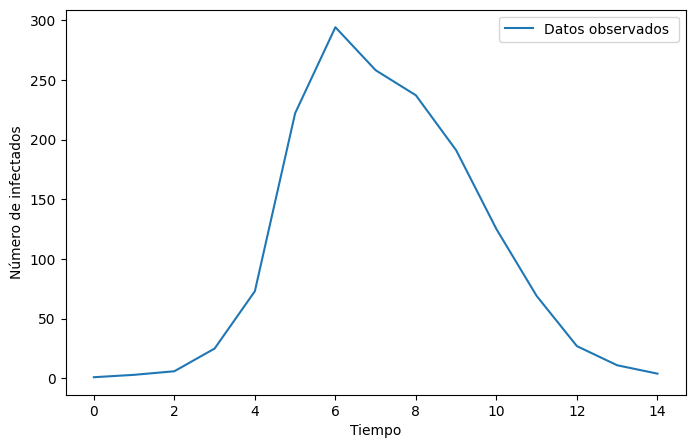

In [3]:
plt.figure(figsize=(8,5))

plt.plot(t,data, label = "Datos observados ")
plt.xlabel("Tiempo")
plt.ylabel("Número de infectados")
plt.legend()
plt.show()



Para representar la evolución de la enfermedad se utiliza el modelo SIR, el cual divide a la población en tres grupos:

- $S(t)$ : individuos suceptibles.
- $I(t)$ : individuos infectados.
- $R(t)$ : individuos recuperados.

La dinámica del modelo está dada por:

$$
\frac{dS}{dt}=-aSI,
$$

$$
\frac{dI}{dt}=aSI-bI,
$$

$$
\frac{dR}{dt}=bI.
$$

donde $a$ representa la tasa de infección y $b$ la tasa de recuperación.

A diferencia del ajuste realizado anteriormente mediante Metropolis-Hastings,
en esta actividad los parámetros $a$ y $b$ serán tratados desde un enfoque
bayesiano. Por lo tanto, se les asignarán distribuciones a priori y, utilizando
los datos observados, se obtendrán sus distribuciones posteriores mediante PyMC.

###Condiciones iniciales

Se considera una población total de $N=1000$ individuos. El primer dato
observado corresponde a un individuo infectado y se supone que inicialmente
no existen individuos recuperados.

Por lo tanto:

$$
N=1000,\qquad I(0)=1,\qquad R(0)=0,
$$

y el número inicial de susceptibles es

$$
S(0)=1000-1-0=999.
$$

Así, las condiciones iniciales del sistema son

$$
(S_0,I_0,R_0)=(999,1,0).
$$

In [4]:
from __future__ import print_function
#Poblacion total

N=1000

#Condiciones Iniciales
I0 = data[0]
R0 = 0
S0 = N - I0 - R0

Y0 = [S0,I0,R0]

print("S0 = ", S0)
print("I0 = ",I0)
print("R0=", R0)

S0 =  999
I0 =  1
R0= 0


##Enfoque Bayesiano

En el enofoque bayesiano los parámetros del modelo no se consideran valores fijos, sino variables aleatorias.

Para los parámetros $a$ y $b$ del modelo SIR se asignan distribuciones **a priori**, que representan el conocimiento sobre los parámetros antes de considerar los datos observados.

Posterirormente, la información de los datos se incorpora mediante una función de verosimilitud. Aplicando el teorema de Bayes se obtiene la distribución posterior:

$$
p(a,b\ D) =
\frac{p(D\mid a,b) \, p(a,b)}{p(D)},
$$

Donde $D$ representara los datos observados.

La distribución posterior permitirá estimar los valores más probables de $a$ y $b$, así como cuantificar la incertidumbre asociada a su estimación.

##Distribución a priori.

Debido a que los parámetros $a$ y $b$ representan tasas, sus valores deben de ser positivos. Por esta razón se utilizarán distribuciones Half-Normal como distribución a priori:

$$
a\sim \operatorname{Half-Normal}(\sigma = 0.01)
$$

$$
b\sim \operatorname{Half-Normal}(\sigma = 1)
$$

Estas distribuciones restringen los parámetros a valores positivos y permiten que posteriormente los datos actualicen la información disponible sobre ellos.


##Implementación del modelo SIR en PyMC
Para realizar la inferencia bayesiana, PyMC necesita evaluar el modelo SIR para diferentes valores de los parámetros $a$ y $b$.

Se define entonces el sistema de ecuaciones diferenciales del modelo:

$$
\frac{dS}{dt} = aSI,
$$

$$
\frac{dI}{dt} = aSI - bI,
$$

$$
frac{dR}{dt} = bI .
$$

Posteriormente, estas ecuaciones serán utilizadas dentro del modelo probabilistico para relacionar los parámetros $a$ y $b$ con los datos obsesrvados de individuos infectados.


In [5]:
from pymc.ode import DifferentialEquation

In [6]:
#Sistema de ecuaciones diferenciales SIR:
def sir_ode(y,t,p):
  S = y[0]
  I = y[1]
  R = y[2]

  a = p[0]
  b = p[1]

  dS = -a*S*I
  dI = a*S*I - b*I
  dR = b*I

  return [dS,dI,dR]

In [7]:
sir_model = DifferentialEquation(
    func = sir_ode,
    times = t,
    n_states = 3,
    n_theta = 2,
    t0 = 0
)

##Construccion del Modelo Bayesiano.

Una vez hemos definido el sistema SIR, se construye el modelo probabilistico en Pymc.

Los parámetros $a$ y $b$ se consideran variables aleatorias positivas con las distribuciones a priori definidas anteriormente. Para representar las variabilidad entre los valores generados por el modelo SIR y los datos observados introduciremos un parametro $\sigma$.

$$
I_{\text{obs}}(t)\sim
\mathcal{N}\left(I_{\text{SIR}}(t),\sigma\right).
$$

De esta manerá, PyMC combinará las distribuciones a priori con la información contenida en los datos para obtener las distribuciones posteriores a los parámetros.

In [8]:
with pm.Model() as Modelo_Bayesiano:
  #Distribucion a Priori
  a = pm.HalfNormal('a', sigma = 0.01)
  b = pm.HalfNormal('b', sigma = 1)
#Variabilidad de las observaciones.
  sigma = pm.HalfNormal('sigma', sigma = 50)
#sol del sitema SIR
  sir_solution = sir_model(
      Y0,
      [a,b]
  )
#tomamos solo componentes de los infectados:
  I_model = sir_solution[:,1]

#Verosilimitud:
  I_obs = pm.Normal('I_obs',
                  mu = I_model,
                  sigma = sigma,
                  observed = data)
  ##nota para mi: nmms si jalo jjsjs

##Muestreo de la distribucion posterior.
Una vez definido el modelo probabilístico, se realiza el muestreo de las distribuciones posteriores de los parámetros mediante PyMC.

Se genera varias cadenas independientes, lo que permite posteriormente evaluar la convergencia del procedimiento y analizar la incertidumbre de los parametros $a$ y $b$.

El objetivo es obtener muestras de:
$$
p(a,b,\sigma\mid D),
$$
es decir, la distribución de los parámetros condicionada a los datos observados.

In [9]:
with Modelo_Bayesiano:
  idata= pm.sample(
      draws = 1000,
      tune = 500,
      chains = 2,
      cores = 2,
      target_accept = 0.9,
      random_seed = 42,
      return_inferencedata = True
  )

 Progress                       Draw   Divergences   Step size   Grad evals   Speed          Elapsed   Remaining  
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━   1500   0             0.630       3            1.18 s/draw    0:29:30   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━   1500   0             0.493       5            1.08 draws/s   0:23:05   0:00:00

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
idata.to_netcdf(
    "/content/drive/MyDrive/resultado_sir_pymc.nc"
)

print("Muestras guardadas correctamente")

In [12]:
az.summary(idata, var_names=["a", "b", "sigma"])

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,0.002,0.000,0.002,0.002,0.000,0.000,1067.0,1282.0,1.0
b,0.586,0.019,0.554,0.627,0.001,0.000,1141.0,1259.0,1.0
sigma,19.120,4.022,12.561,26.589,0.125,0.119,1039.0,1011.0,1.0


###Análisis de las distribuciones posteriores

Una vez obtenidas las muestras, se analiza el comportamiento de las cadenas
y las distribuciones posteriores de los parámetros.

Las gráficas de traza permiten observar tanto la distribución de los valores
muestreados como la evolución de cada cadena durante el proceso de muestreo.
Esto permite evaluar visualmente si las cadenas presentan un comportamiento
estable y si exploran regiones similares del espacio de parámetros.

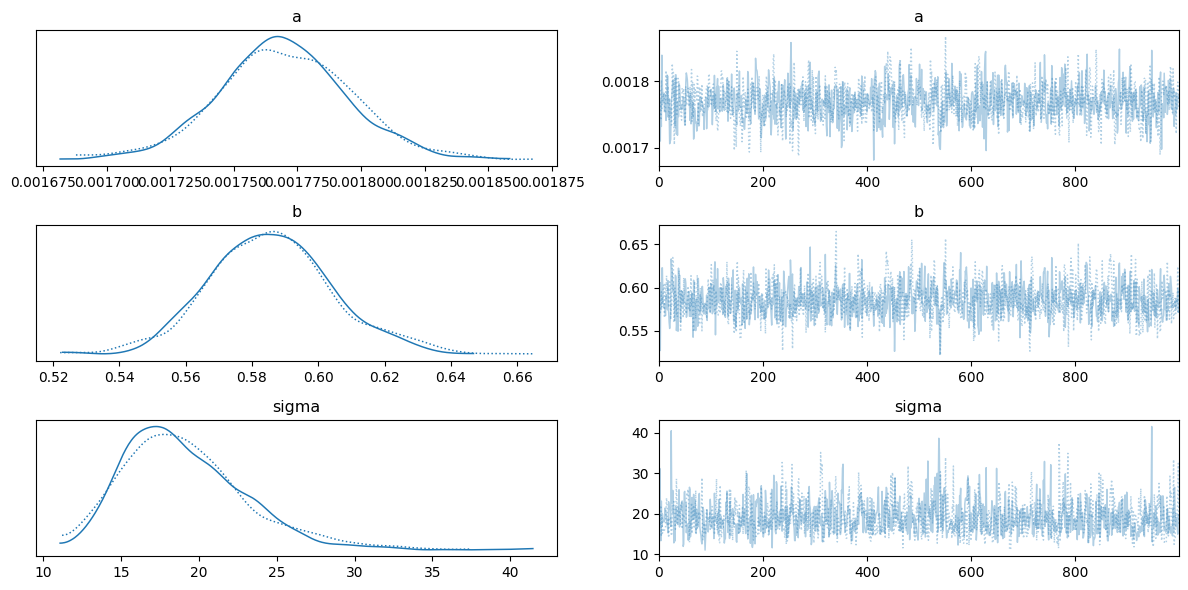

In [13]:
az.plot_trace(
    idata,
    var_names=["a", "b", "sigma"]
)

plt.tight_layout()
plt.show()

### Interpretación de las trazas

Las distribuciones posteriores muestran que los parámetros se concentran
alrededor de $a\approx0.001770$ y $b\approx0.5859$. El parámetro $\sigma$,
que representa la variabilidad de las observaciones respecto al modelo,
presenta una media aproximada de $19.12$.

En las gráficas de traza se observa que las dos cadenas se mezclan y oscilan
alrededor de regiones estables, sin presentar tendencias sistemáticas. Este
comportamiento, junto con valores de $\hat{R}$ cercanos a 1 y la ausencia de
divergencias, proporciona evidencia de una convergencia adecuada del muestreo.

 ##Distribuciones posteriores e intervalos de credibilidad

A partir de las muestras generadas por PyMC se pueden visualizar las
distribuciones posteriores de los parámetros.

Además de una estimación puntual, el enfoque bayesiano permite obtener un
intervalo de densidad posterior alta (HDI), que representa la región donde se
concentra una proporción determinada de la probabilidad posterior.

En este caso se utiliza un HDI del $94\%$ para analizar la incertidumbre
asociada a los parámetros $a$, $b$ y $\sigma$.

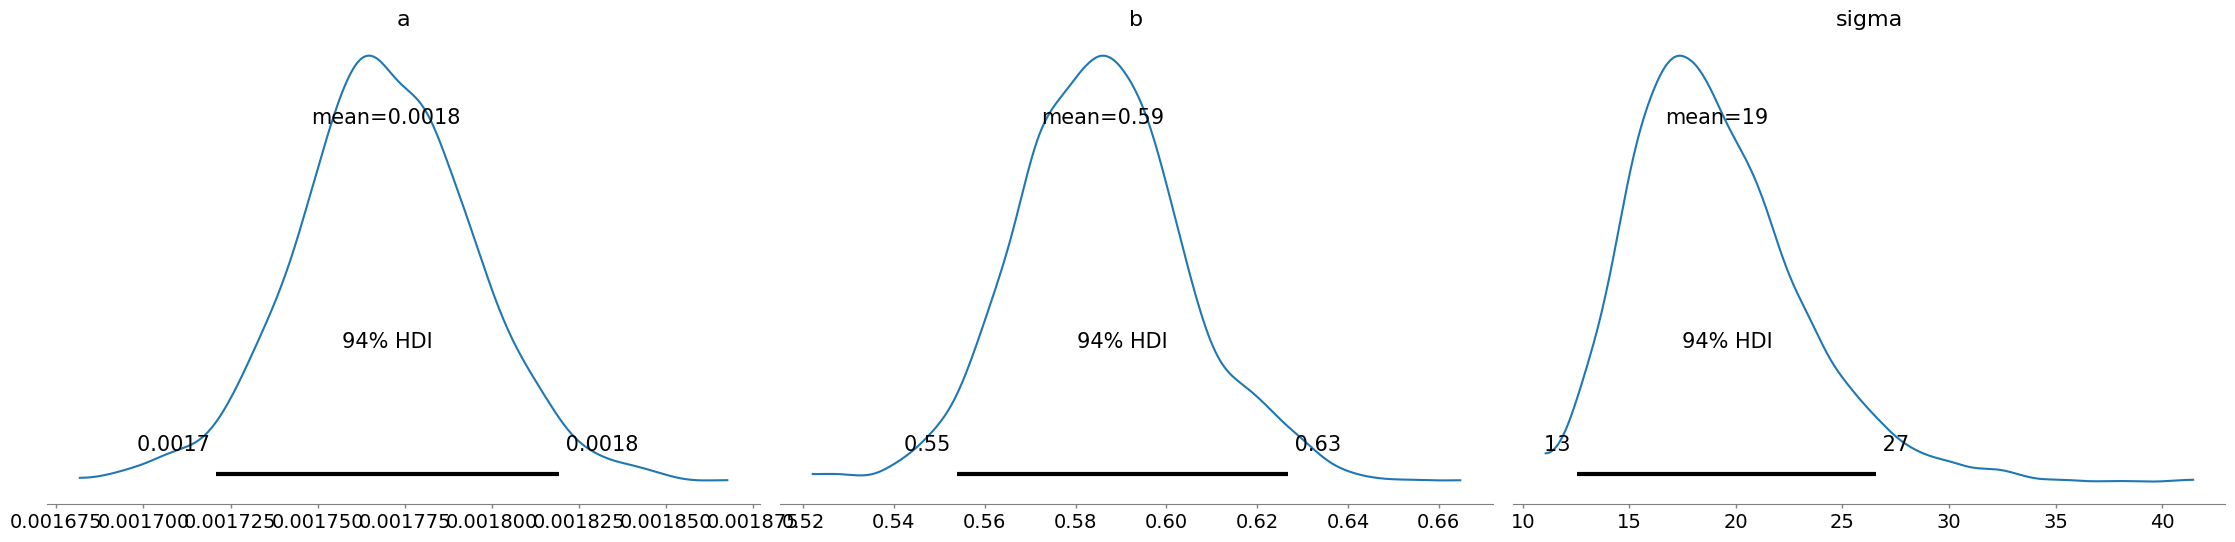

In [14]:
az.plot_posterior(
    idata,
    var_names=["a", "b", "sigma"],
    hdi_prob=0.94
)

plt.tight_layout()
plt.show()

Ajuste del modelo SIR con los parámetros estimados

Una vez obtenidas las distribuciones posteriores, se utilizan los valores
medios estimados de $a$ y $b$ para resolver nuevamente el sistema SIR.

El objetivo es comparar la trayectoria de individuos infectados generada por
el modelo con los datos observados. Esta comparación permite evaluar
visualmente qué tan bien los parámetros estimados mediante PyMC reproducen
la evolución observada de los infectados.

In [15]:
from scipy.integrate import odeint

In [16]:
# Medias posteriores de los parámetros
a_mean = idata.posterior["a"].mean().item()
b_mean = idata.posterior["b"].mean().item()

print("a =", a_mean)
print("b =", b_mean)

a = 0.001769587906985811
b = 0.5858852479510783


In [17]:
# Modelo SIR para la representación final
def sir_final(y, t, a, b):
    S, I, R = y

    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I

    return dSdt, dIdt, dRdt


# Solución utilizando las medias posteriores
solucion_final = odeint(
    sir_final,
    Y0,
    t,
    args=(a_mean, b_mean)
)

I_final = solucion_final[:, 1]

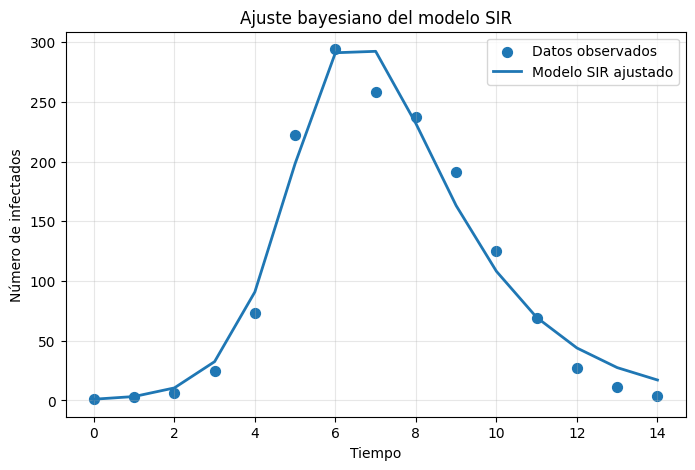

In [19]:
plt.figure(figsize=(8, 5))

# Datos reales
plt.scatter(
    t,
    data,
    label="Datos observados",
    s=50
)

# Modelo ajustado
plt.plot(
    t,
    I_final,
    label="Modelo SIR ajustado",
    linewidth=2
)

plt.xlabel("Tiempo")
plt.ylabel("Número de infectados")
plt.title("Ajuste bayesiano del modelo SIR")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

### Interpretación del ajuste

La curva obtenida mediante el modelo SIR reproduce adecuadamente el
comportamiento general de los datos observados. Se identifica una etapa inicial
de crecimiento, seguida por un máximo de individuos infectados y posteriormente
una disminución progresiva.

Los valores observados no coinciden exactamente con la curva en todos los
instantes, debido a la variabilidad presente en los datos y a las simplificaciones
propias del modelo SIR. Esta incertidumbre es considerada en el modelo bayesiano
mediante el parámetro $\sigma$.

En general, los parámetros estimados mediante PyMC permiten representar de
manera adecuada la dinámica observada de los individuos infectados.

## Resultados finales

El ajuste bayesiano del modelo SIR mediante PyMC permitió obtener las
distribuciones posteriores de los parámetros $a$, $b$ y $\sigma$.

Las medias posteriores obtenidas fueron aproximadamente:

$$
\boxed{a = 0.001770}
$$

$$
\boxed{b = 0.5859}
$$

$$
\boxed{\sigma = 19.12}
$$

Para los parámetros principales del modelo, los intervalos HDI del $94\%$
fueron aproximadamente:

$$
a \in [0.001721,\;0.001819],
$$

$$
b \in [0.5539,\;0.6268].
$$

Los valores de $\hat{R}$ fueron aproximadamente iguales a 1 y los tamaños
efectivos de muestra (ESS) fueron superiores a 1000. Además, durante el
muestreo no se presentaron divergencias. Estos resultados proporcionan
evidencia de un comportamiento adecuado de las cadenas utilizadas para
la inferencia.

##  Conclusiones

En esta actividad se realizó el ajuste de los parámetros del modelo SIR
utilizando un enfoque bayesiano mediante la librería PyMC.

A diferencia de una estimación únicamente puntual, el enfoque bayesiano
permitió obtener distribuciones posteriores para los parámetros y cuantificar
la incertidumbre asociada a sus valores.

Las estimaciones obtenidas fueron $a\approx0.001770$ y $b\approx0.5859$.
Las gráficas de traza, los valores de $\hat{R}$ cercanos a 1, los tamaños
efectivos de muestra y la ausencia de divergencias indican un comportamiento
adecuado del muestreo.

Finalmente, al utilizar los parámetros estimados en el sistema SIR, la curva
resultante reprodujo el comportamiento general de los datos observados:
crecimiento inicial de los infectados, aparición de un máximo y posterior
disminución.

Por lo tanto, el enfoque bayesiano con PyMC permitió estimar los parámetros
del modelo SIR y, al mismo tiempo, analizar la incertidumbre asociada a dichas
estimaciones.